Predicting Stock Market Prices	
Calculate daily logarithmic returns of TSLA stock and construct visual distributions to assess return volatility and risk, supporting advanced financial analysis and decision-making.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Load dataset and sort chronologically
df = pd.read_csv('TSLA_cleaned_data.csv')
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

df[['Date', 'Close']].head()

,Date,Close
0,2025-01-02,381.88
1,2025-01-03,376.36
2,2025-01-06,380.68
3,2025-01-07,386.06
4,2025-01-08,375.53


In [2]:
# Compute daily logarithmic returns: ln(Close_t / Close_{t-1})
df['Log_Return'] = np.log(df['Close'] / df['Close'].shift(1))
log_returns = df['Log_Return'].dropna()

# Core return, volatility, and tail-risk metrics
mean_ret = log_returns.mean()
std_ret = log_returns.std()
ann_vol = std_ret * np.sqrt(252)  # Annualized volatility (252 trading days)
skewness = stats.skew(log_returns)
kurtosis = stats.kurtosis(log_returns)  # Excess kurtosis
var_95 = np.percentile(log_returns, 5)
var_99 = np.percentile(log_returns, 1)

print("--- TSLA Daily Log Return & Volatility Summary ---")
print(f"Valid Trading Days : {len(log_returns)}")
print(f"Mean Daily Return  : {mean_ret:.6f} ({mean_ret*100:.4f}%)")
print(f"Median Daily Return: {log_returns.median():.6f} ({log_returns.median()*100:.4f}%)")
print(f"Daily Volatility   : {std_ret:.6f} ({std_ret*100:.4f}%)")
print(f"Annualized Vol.    : {ann_vol:.4f} ({ann_vol*100:.2f}%)")
print(f"Min / Max Return   : {log_returns.min()*100:.2f}% / {log_returns.max()*100:.2f}%")
print(f"Skewness           : {skewness:.4f}")
print(f"Excess Kurtosis    : {kurtosis:.4f}")
print(f"Historical VaR 95% : {var_95*100:.2f}% (1-day 95% confidence loss threshold)")
print(f"Historical VaR 99% : {var_99*100:.2f}% (1-day 99% confidence loss threshold)")

--- TSLA Daily Log Return & Volatility Summary ---
Valid Trading Days : 99
Mean Daily Return  : 0.000337 (0.0337%)
Median Daily Return: 0.000299 (0.0299%)
Daily Volatility   : 0.010299 (1.0299%)
Annualized Vol.    : 0.1635 (16.35%)
Min / Max Return   : -2.77% / 3.03%
Skewness           : -0.1768
Excess Kurtosis    : 0.1058
Historical VaR 95% : -1.67% (1-day 95% confidence loss threshold)
Historical VaR 99% : -2.28% (1-day 99% confidence loss threshold)


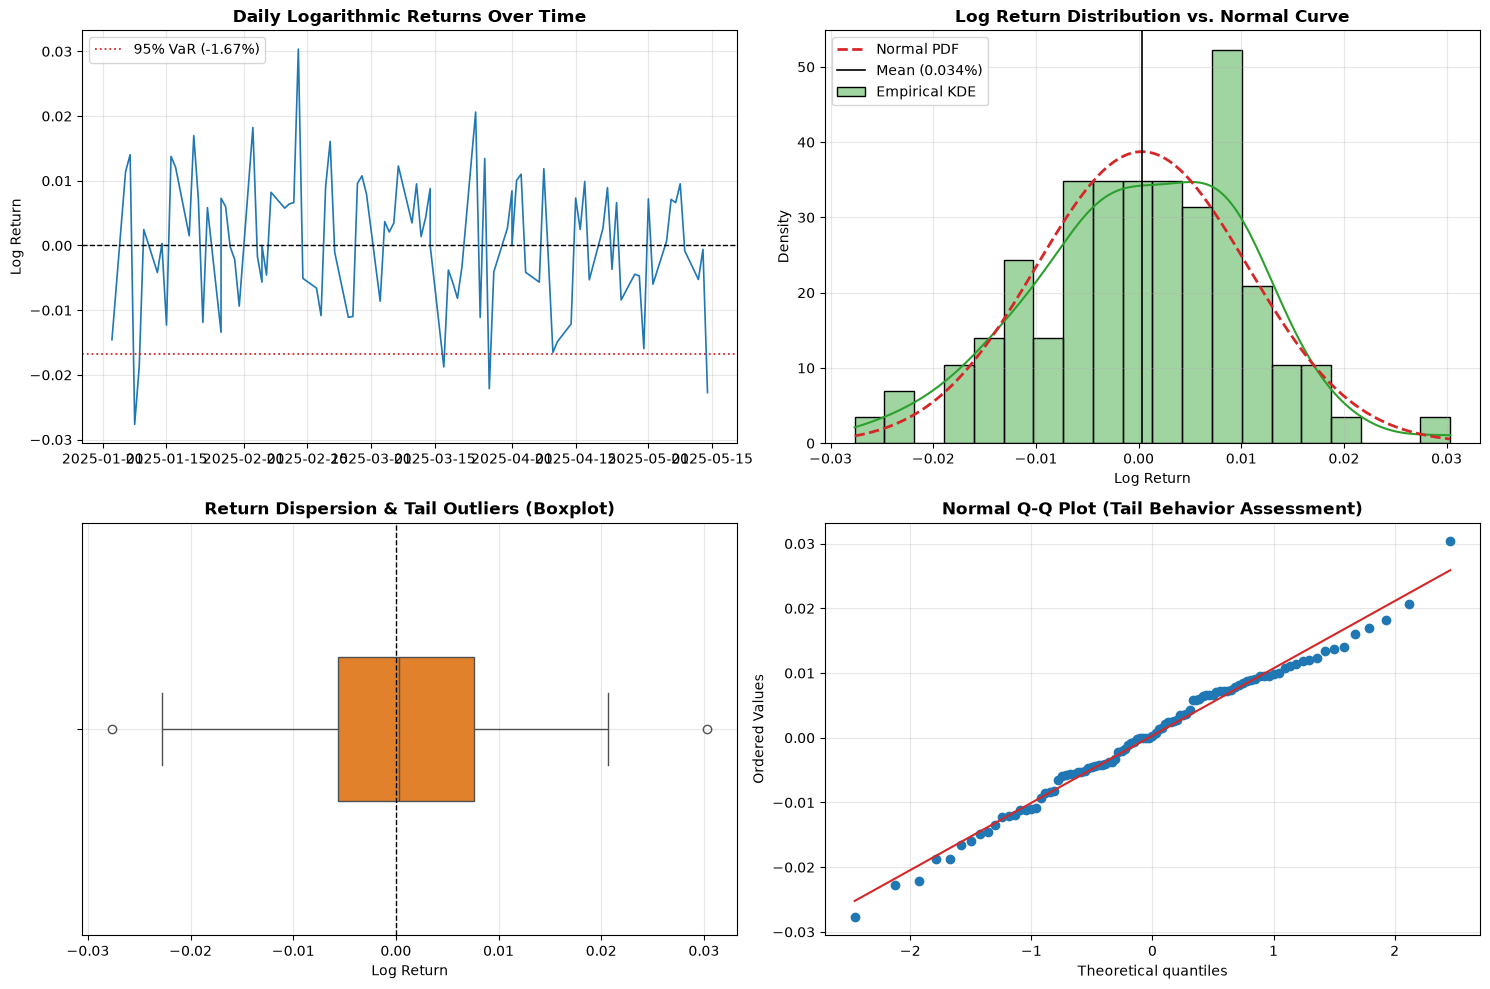

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Time-Series of Daily Log Returns (Volatility Clustering)
axes[0, 0].plot(df['Date'], df['Log_Return'], color='#1f77b4', linewidth=1.2)
axes[0, 0].axhline(0, color='black', linestyle='--', linewidth=1)
axes[0, 0].axhline(var_95, color='#d62728', linestyle=':', linewidth=1.3, label=f'95% VaR ({var_95*100:.2f}%)')
axes[0, 0].set_title('Daily Logarithmic Returns Over Time', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Log Return')
axes[0, 0].legend(loc='upper left')
axes[0, 0].grid(True, alpha=0.3)

# 2. Histogram + KDE vs. Theoretical Normal Distribution
sns.histplot(log_returns, bins=20, kde=True, stat='density', color='#2ca02c', alpha=0.45, ax=axes[0, 1], label='Empirical KDE')
x_vals = np.linspace(log_returns.min(), log_returns.max(), 200)
axes[0, 1].plot(x_vals, stats.norm.pdf(x_vals, mean_ret, std_ret), color='#d62728', linestyle='--', linewidth=2, label='Normal PDF')
axes[0, 1].axvline(mean_ret, color='black', linestyle='-', linewidth=1.2, label=f'Mean ({mean_ret*100:.3f}%)')
axes[0, 1].set_title('Log Return Distribution vs. Normal Curve', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Log Return')
axes[0, 1].legend(loc='upper left')
axes[0, 1].grid(True, alpha=0.3)

# 3. Boxplot for Tail Outliers & IQR Spread
sns.boxplot(x=log_returns, color='#ff7f0e', ax=axes[1, 0], width=0.35)
axes[1, 0].axvline(0, color='black', linestyle='--', linewidth=1)
axes[1, 0].set_title('Return Dispersion & Tail Outliers (Boxplot)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Log Return')
axes[1, 0].grid(True, alpha=0.3)

# 4. Q-Q Plot (Normality & Tail-Risk Check)
stats.probplot(log_returns, dist='norm', plot=axes[1, 1])
axes[1, 1].get_lines()[0].set_color('#1f77b4')
axes[1, 1].get_lines()[1].set_color('#d62728')
axes[1, 1].set_title('Normal Q-Q Plot (Tail Behavior Assessment)', fontsize=12, fontweight='bold')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()